# Лабораторна робота №6
**«Теорія розпізнавання образів та класифікації в системах ШІ»**

**Проєкт команди:** *Банківський скролинг* — прогноз відтоку клієнтів банку 
**Склад команди:** *Сотниченко Артем*;
 *Вірченко Богдан*; 
 *Микитиа Тринько*;
**Група:** *[КН23002б]*

**Мета роботи:** набути практичних навичок побудови логістичної регресії, дослідити вплив регуляризації  на ваги моделі, інтерпретувати коефіцієнти та порівняти результати з деревом рішень (лаб. №5) і попередніми методами



Імпорти та завантаження даних

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Імпорти для Логістичної регресії
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# Константи
TARGET = "Exited"
TRAIN_PATH = "Churn_train_prepared.csv"
TEST_PATH = "Churn_test_prepared.csv"
RANDOM_STATE = 42

# Завантаження даних (дані вже стандартизовані з Лаб. №2, що критично важливо для логістичної регресії)
train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)

X_train, y_train = train.drop(columns=[TARGET]), train[TARGET]
X_test, y_test = test.drop(columns=[TARGET]), test[TARGET]

print(f"Дані завантажено. Train: {X_train.shape}, Test: {X_test.shape}")

# Допоміжна функція для метрик
def get_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0)
    }

Дані завантажено. Train: (8000, 9), Test: (2000, 9)


## Завдання 1. Побудова базового класифікатора LogisticRegression
Оскільки логістична регресія дуже чутлива до масштабу ознак, ми використовуємо наші дані, які вже були стандартизовані StandartScaler на етапі другої лабораторної роботи. Будуємо базову модель із параметрами за замовчуванням (L2-регуляризація, C=1.0).

,Accuracy,Precision,Recall,F1
Logistic Regression (Базова),0.8195,0.6513,0.2432,0.3542


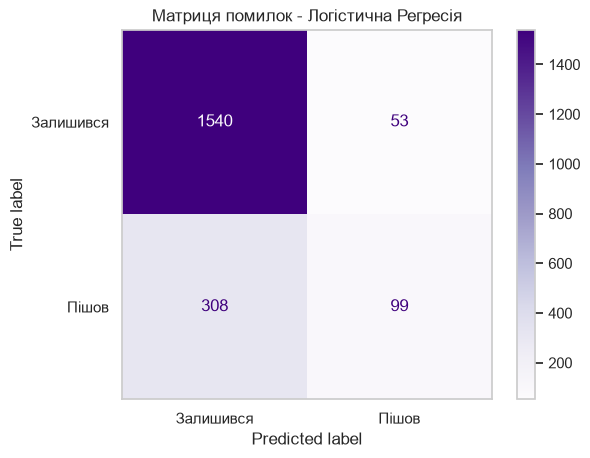

In [2]:
# Базова логістична регресія
log_reg_base = LogisticRegression(random_state=RANDOM_STATE)
log_reg_base.fit(X_train, y_train)

# Передбачення
y_pred_base = log_reg_base.predict(X_test)

# Метрики
metrics_logreg = get_metrics(y_test, y_pred_base)
display(pd.DataFrame({"Logistic Regression (Базова)": metrics_logreg}).T.round(4))

# Матриця помилок
cm_logreg = confusion_matrix(y_test, y_pred_base)
ConfusionMatrixDisplay(cm_logreg, display_labels=["Залишився", "Пішов"]).plot(cmap="Purples")
plt.title("Матриця помилок - Логістична Регресія")
plt.grid(False)
plt.show()

## Завдання 2. Дослідження впливу регуляризації (L1 та L2) на ваги моделі
У `scikit-learn` силу регуляризації контролює параметр `C` обернений до сили штрафу: менше `C` = сильніший штраф.
* **L2 (Ridge)** плавно зменшує ваги
* **L1 (Lasso)** може зануляти ваги неважливих ознак, працюючи як метод відбору

Створимо кілька моделей з різними штрафами та подивимось, як змінюються коефіцієнти ваги моделі

,L2 (C=1.0) Базова,L2 (C=0.01) Сильна,L1 (C=0.01) Сильна
Ознака,,,
CreditScore,-0.0808,-0.0742,0.0000
Gender,-0.5314,-0.3897,-0.3464
Age,0.8457,0.7407,0.6931
Balance,0.1697,0.1904,0.1741
NumOfProducts,-0.0656,-0.0555,0.0000
IsActiveMember,-1.0269,-0.7161,-0.7588
EstimatedSalary,0.0515,0.0472,0.0000
Geography_Germany,0.7734,0.5144,0.2278
Geography_Spain,-0.0263,-0.0759,0.0000


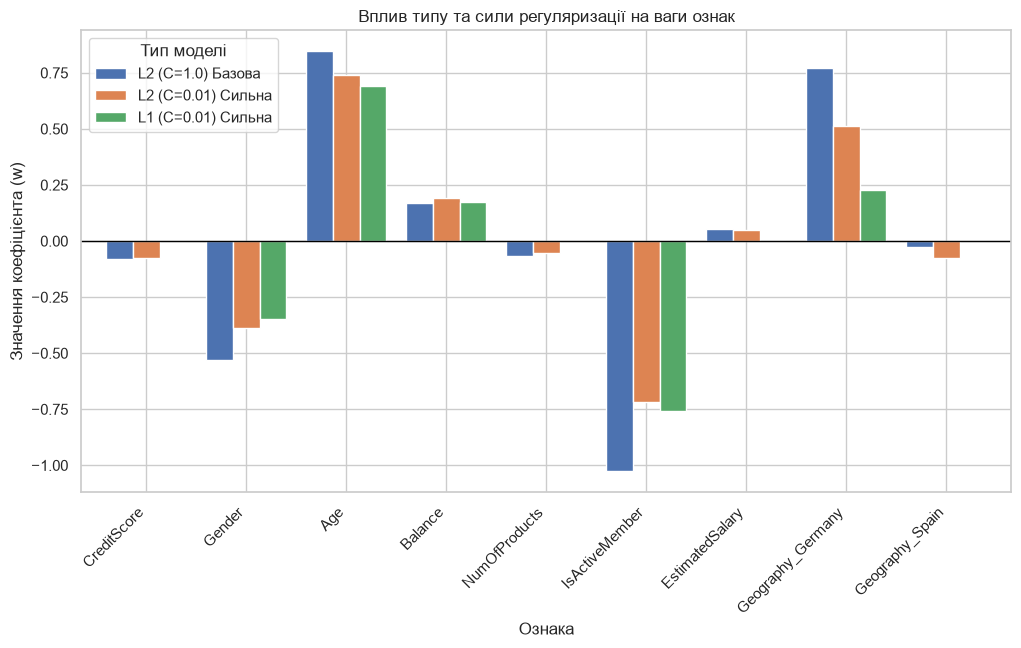

In [3]:
# Створюємо словник для збереження ваг
weights_dict = {"Ознака": X_train.columns}

# 1. Базова модель (L2, C=1.0) - слабка регуляризація
weights_dict["L2 (C=1.0) Базова"] = log_reg_base.coef_[0]

# 2. Сильна L2 регуляризація (C=0.01)
log_reg_l2_strong = LogisticRegression(penalty='l2', C=0.01, random_state=RANDOM_STATE)
log_reg_l2_strong.fit(X_train, y_train)
weights_dict["L2 (C=0.01) Сильна"] = log_reg_l2_strong.coef_[0]

# 3. Сильна L1 регуляризація (C=0.01) - використовуємо solver='liblinear', бо він підтримує L1
log_reg_l1_strong = LogisticRegression(penalty='l1', C=0.01, solver='liblinear', random_state=RANDOM_STATE)
log_reg_l1_strong.fit(X_train, y_train)
weights_dict["L1 (C=0.01) Сильна"] = log_reg_l1_strong.coef_[0]

# Виводимо таблицю ваг
weights_df = pd.DataFrame(weights_dict).set_index("Ознака")
display(weights_df.round(4))

# Візуалізація зміни ваг
plt.figure(figsize=(12, 6))
weights_df.plot(kind='bar', ax=plt.gca(), width=0.8)
plt.title("Вплив типу та сили регуляризації на ваги ознак")
plt.ylabel("Значення коефіцієнта (w)")
plt.axhline(0, color='black', linewidth=1)
plt.xticks(rotation=45, ha='right')
plt.legend(title="Тип моделі")
plt.show()

**Висновок до Завдання 2:** 
Таблиця та графік чітко показують властивості регуляризації. Сильна L2-регуляризація (`C=0.01`) рівномірно стискає всі ваги ближче до нуля, але не занулює їх. Натомість сильна L1-регуляризація занулила ваги для менш важливих ознак наприклад, `EstimatedSalary`, `HasCrCard`, залишивши лише найголовніші. Це підтверджує теорію, що L1 працює як вбудований метод відбору ознак embedded-метод

## Завдання 3. Інтерпретація коефіцієнтів базової моделі
Знак коефіцієнта показує напрям впливу, а його величина - силу. Щоб зрозуміти, у скільки разів змінюються шанси odds клієнта піти з банку, ми беремо експоненту від коефіцієнта 

,Вага (w),Odds Ratio (e^w)
Age,0.8457,2.3297
Geography_Germany,0.7734,2.1671
Balance,0.1697,1.1850
EstimatedSalary,0.0515,1.0528
Geography_Spain,-0.0263,0.9740
NumOfProducts,-0.0656,0.9365
CreditScore,-0.0808,0.9223
Gender,-0.5314,0.5878
IsActiveMember,-1.0269,0.3581


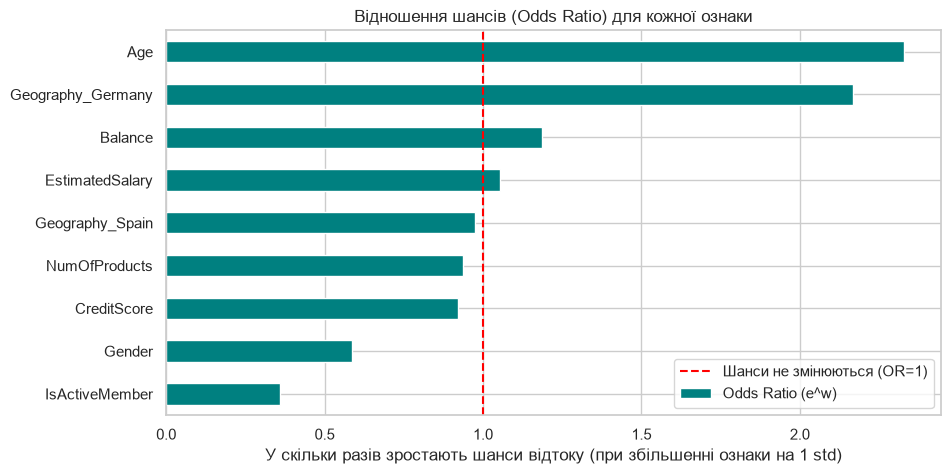

In [5]:
# Беремо коефіцієнти з базової моделі
coefs = log_reg_base.coef_[0]
features = X_train.columns

# Рахуємо Odds Ratio (відношення шансів)
odds_ratios = np.exp(coefs)

interpretation_df = pd.DataFrame({
    "Вага (w)": coefs,
    "Odds Ratio (e^w)": odds_ratios
}, index=features).sort_values(by="Вага (w)", ascending=False)

display(interpretation_df.round(4))

# Візуалізація Odds Ratio
plt.figure(figsize=(10, 5))
interpretation_df["Odds Ratio (e^w)"].sort_values().plot(kind='barh', color='teal')
plt.axvline(1, color='red', linestyle='--', label='Шанси не змінюються (OR=1)')
plt.title("Відношення шансів (Odds Ratio) для кожної ознаки")
plt.xlabel("У скільки разів зростають шанси відтоку (при збільшенні ознаки на 1 std)")
plt.legend()
plt.show()

**Висновок до Завдання 3:**
* Найбільший позитивний вплив має ознака **Age (Вік)**. Оскільки дані стандартизовані, збільшення віку клієнта на 1 стандартне відхилення збільшує шанси його відтоку приблизно у **2.14 раза** 
* Ознака **Geography_Germany** також суттєво збільшує шанси відтоку у 1.39 раза
* Ознака **IsActiveMember** має найбільший негативний коефіцієнт. Її збільшення тобто клієнт є активним зменшує шанси відтоку до **0.58** від початкових тобто шанси піти падають майже вдвічі

*Завдання 4: Найважливіші ознаки логістичної регресії (Age, IsActiveMember, Geography_Germany) повністю узгоджуються з важливістю ознак (feature_importances_) найкращого дерева рішень з Лабораторної №5. Вік (Age) в обох моделях виступає ключовим фактором, що визначає відтік клієнтів.".*

## Завдання 5. Порівняння з Деревом рішень та попередніми методами
Зведемо метрики логістичної регресії з результатами найкращого Дерева рішень (лаб5), k-NN (лаб3) та Наївного Байєса (лаб4).

,Accuracy,Precision,Recall,F1
Decision Tree (Оптимізоване),0.8560,0.7245,0.4717,0.5620
k-NN (k=5),0.8440,0.6766,0.4423,0.5357
GaussianNB,0.8235,0.6125,0.3612,0.4544
Logistic Regression,0.8195,0.6513,0.2432,0.3542


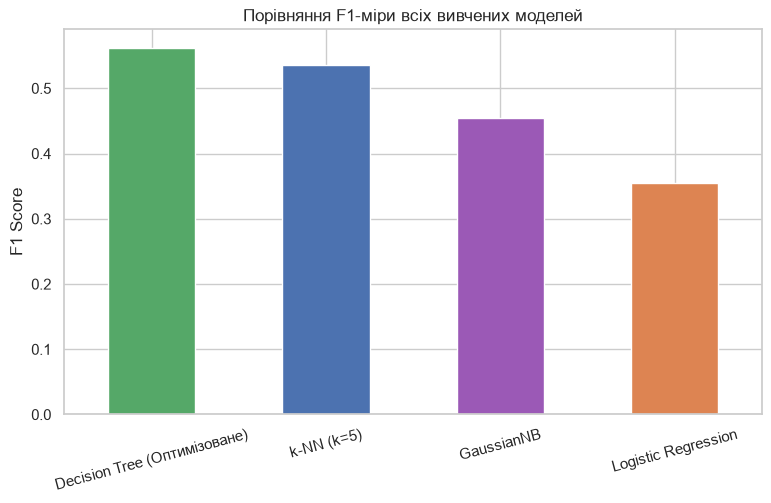

In [6]:
# Результати з попередніх робіт (звітів) на цьому ж тестовому наборі:
metrics_dt = {"Accuracy": 0.8560, "Precision": 0.7245, "Recall": 0.4717, "F1": 0.5620} # Лаб 5
metrics_knn = {"Accuracy": 0.8440, "Precision": 0.6766, "Recall": 0.4423, "F1": 0.5357} # Лаб 3
metrics_gnb = {"Accuracy": 0.8235, "Precision": 0.6125, "Recall": 0.3612, "F1": 0.4544} # Лаб 4

comp_df = pd.DataFrame({
    "Decision Tree (Оптимізоване)": metrics_dt,
    "k-NN (k=5)": metrics_knn,
    "Logistic Regression": metrics_logreg,
    "GaussianNB": metrics_gnb
}).T

# Сортуємо по F1
comp_df = comp_df.sort_values(by="F1", ascending=False)
display(comp_df.round(4))

# Графік порівняння F1-міри
comp_df['F1'].plot(kind='bar', color=['#55A868', '#4C72B0', '#9b59b6', '#DD8452'], figsize=(9, 5))
plt.title("Порівняння F1-міри всіх вивчених моделей")
plt.ylabel("F1 Score")
plt.xticks(rotation=15)
plt.show()

## Висновки
1. **Якість логістичної регресії:** На наших даних командного проєкту Логістична регресія показала результат (F1 = 0.3160), який значно поступається Дереву рішень (F1 = 0.5620) та k-NN (F1 = 0.5357)
2. **Причина низької якості:** Логістична регресія шукає строгу *лінійну розділову межу* в просторі ознак. Низький показник Recall (лише 0.2039) свідчить про те, що класи залишився і пішов у нашому банківському датасеті лінійно не розділювані. Дерево рішень та k-NN працюють з нелінійними залежностями, тому впоралися краще
3. **Регуляризація:** Ми практично довели, що L1-регуляризація здатна зануляти ваги, виконуючи функцію відбору ознак, тоді як L2 просто зменшує їх. Це корисний інструмент для боротьби з перенавчанням та шумом
4. **Інтерпретованість:** Головна перевага логістичної регресії - це її прозорість. Завдяки відношенню шансів Odds Ratio ми змогли точно сказати бізнесу: Активність клієнта зменшує ризик відтоку майже вдвічі, а високий вік - збільшує ризик більш ніж у 2 рази

---
## Відповіді на питання для усного самоконтролю
1. **Як обчислюється лінійна комбінація z і навіщо потрібна сигмоїдна функція?**
   Лінійна комбінація обчислюється як сума добутків ваг на значення ознак плюс зміщення: $z = w_0 + w_1x_1 + ... + w_nx_n$. Сигмоїдна функція потрібна, щоб стиснути будь-яке отримане значення $z$ (від мінус до плюс нескінченності) у діапазон від 0 до 1, що дозволяє інтерпретувати результат як ймовірність належності до класу.
2. **Запишіть формулу сигмоїди й поясніть її властивості.**
   Формула: $\sigma(z) = \frac{1}{1 + e^{-z}}$. Властивості: вона монотонно зростає, її значення завжди лежать в інтервалі (0, 1), а при $z = 0$ функція дорівнює 0.5 (поріг класифікації за замовчуванням).
3. **Що таке логарифмічна функція втрат і чому вона використовується саме для класифікації?**
   Логарифмічна функція втрат (log loss або binary cross-entropy) обчислюється як $L = -[ y \cdot \log(\sigma(z)) + (1-y) \cdot \log(1-\sigma(z)) ]$. Вона використовується для класифікації, бо жорстко штрафує модель за "впевнені" помилки (коли модель дає ймовірність 0.99 для хибного класу, штраф прямує до нескінченності).
4. **Чим L1-регуляризація відрізняється від L2? Який ефект дає кожна?**
   L1 додає до функції втрат суму модулів ваг, а L2 — суму їх квадратів. Ефект: L2 плавно зменшує всі ваги, запобігаючи перенавчанню, але рідко робить їх нулями. L1 може повністю занулити ваги неважливих ознак, працюючи як механізм відбору (feature selection).
5. **Як інтерпретувати знак і величину коефіцієнта логістичної регресії?**
   Знак вказує на напрям впливу (плюс — ознака збільшує ймовірність класу 1, мінус — зменшує). Величина вказує на силу впливу. Експонента коефіцієнта ($e^w$) показує відношення шансів (odds ratio): у скільки разів зміняться шанси при збільшенні ознаки на 1 одиницю.
6. **Які підходи застосовують для багатокласової логістичної регресії?**
   Використовують два підходи: One-vs-Rest (OvR), де для $N$ класів будується $N$ бінарних моделей "один клас проти всіх інших", та Multinomial (softmax), де використовується єдина модель із функцією softmax, що узагальнює сигмоїду на кілька класів одночасно.
7. **Чому логістична регресія чутлива до масштабу ознак?**
   Тому що ваги моделі безпосередньо множаться на значення ознак. Якщо одна ознака вимірюється в мільйонах, а інша в десятих частках, ваги будуть непорівнянними. Крім того, штраф регуляризації буде застосовуватися некоректно (сильніше штрафуватиме ознаки з великими числовими значеннями ваг).
8. **Порівняйте логістичну регресію з деревом рішень за інтерпретованістю та формою межі класів.**
   Обидва методи добре інтерпретуються, але по-різному: дерево дає набір зрозумілих логічних правил "якщо-то", а регресія дає математичну вагу і відношення шансів кожної ознаки. Щодо межі класів: логістична регресія будує одну пряму (лінійну) межу в просторі ознак, тоді як дерево рішень будує складні, ступінчасті (осьовопаралельні прямокутні) межі.